
## The Quantum Harmonic Oscillator on a Computer 
**Senior Honours Project, Philomena McDonald s2543832**


In [2]:
%load_ext autoreload
%autoreload 2
# autoreload means edits to the .py files in functions/ are picked up without restarting the kernel

import numpy as np
import matplotlib.pyplot as plt

from functions import (
    local_action,
    metropolis_sweep,
    harmonic,
    anharmonic,
    naive_error,
    integrated_auto_correlation,
    correlation,
    jackknife,
    energy_gap,
)

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


**The Harmonic Oscillator Simulation**

In [13]:
np.random.seed(42)   # keeping seed fixed 
#Defining Parameters
#Parameters w/ dimension
h = 1 
m = 1
omega = 1
hbar = 1

delta_tau = 1 #lattice spacing
N_tau = int(50/delta_tau) #size of the lattice, keeping beta=50 throughout the whole thing!

#Dimensionless Variables
m_tilde  = m * delta_tau 
h_tilde = hbar * delta_tau 
omega_tilde = omega * delta_tau

N_therm = 500 # how many of the first sweeps are discarded
N_sweeps = 20000 # how many passes are repeated
N = N_therm + N_sweeps
samples = [] # for calculating the wavefunction

#Initialising
x = []
x_2 = []

x_analytical = 0.0
R = 1 + (omega_tilde**2/2) - omega_tilde*(np.sqrt(1+omega_tilde**2/4))
x_2_analytical = (1 / (2*m_tilde*omega_tilde*np.sqrt(1+omega_tilde**2/4))) * ((1+R**(N_tau))/(1-R**N_tau))

path = np.random.randn(N_tau)
total_acc_rate = []

V = harmonic(m_tilde, omega_tilde) 

#Running Metropolis-Hastings Algorithm
for i in range(N_therm + N_sweeps):
    total_path, acc_rate = metropolis_sweep(path, h, m_tilde, V)
    x.append(np.mean(total_path))
    x_2.append(np.mean(total_path**2))
    total_acc_rate.append(acc_rate)
    if i >= N_therm:
        samples.append(total_path.copy())

# Slicing to get rid of first N_therm sweeps for thermalisation
x_thermalised = np.array(x[N_therm:])
x_2_thermalised = np.array(x_2[N_therm:])
total_acc_rate = np.array(total_acc_rate)

x_mean, x_naive_error = np.mean(x_thermalised), naive_error(x_thermalised)
x_2_mean, x_2_naive_error = np.mean(x_2_thermalised), naive_error(x_2_thermalised)
tau_x,  W_x,  C_x,  tau_run_x  = integrated_auto_correlation(x_thermalised)
tau_x_2, W_x_2, C_x_2, tau_run_x_2 = integrated_auto_correlation(x_2_thermalised)

#2*tau=1+2*A
x_true_error = x_naive_error * np.sqrt(2*tau_x) 
x_2_true_error = x_2_naive_error * np.sqrt(2*tau_x_2)

x_truth_value = (x_mean - x_true_error <= 0 <= x_mean + x_true_error)
x_2_truth_value = (x_2_mean - x_2_true_error <= x_2_analytical <= x_2_mean + x_2_true_error)

print(f"Acceptance rate = {np.mean(total_acc_rate)}")
print("")
print(f"<x>   = {x_mean:.4f} ± {x_true_error:.4f}  (naive {x_naive_error:.4f}) \
      theoretical value within range: {x_truth_value}")
print(f"<x^2> = {x_2_mean:.4f} ± {x_2_true_error:.4f}  (naive {x_2_naive_error:.4f}) \
      theoretical value within range: {x_2_truth_value}")
print(f"tau_int(x)   = {tau_x:.2f}  (W={W_x}),  N_eff = {N_sweeps/(2*tau_x):.0f}")
print(f"tau_int(x^2) = {tau_x_2:.2f}  (W={W_x_2}),  N_eff = {N_sweeps/(2*tau_x_2):.0f}")
print(f"<x> is {abs(x_mean)/x_true_error:.2f} true standard errors from 0")
print(f"<x^2> is {(x_2_mean - x_2_analytical) / x_2_true_error:.2f} true standard errors from the analytical value {np.round(x_2_analytical, 3)}")

Acceptance rate = 0.6748595121951219

<x>   = -0.0001 ± 0.0048  (naive 0.0010)       theoretical value within range: True
<x^2> = 0.4484 ± 0.0024  (naive 0.0007)       theoretical value within range: True
tau_int(x)   = 11.52  (W=58),  N_eff = 868
tau_int(x^2) = 5.19  (W=26),  N_eff = 1925
<x> is 0.01 true standard errors from 0
<x^2> is 0.50 true standard errors from the analytical value 0.447


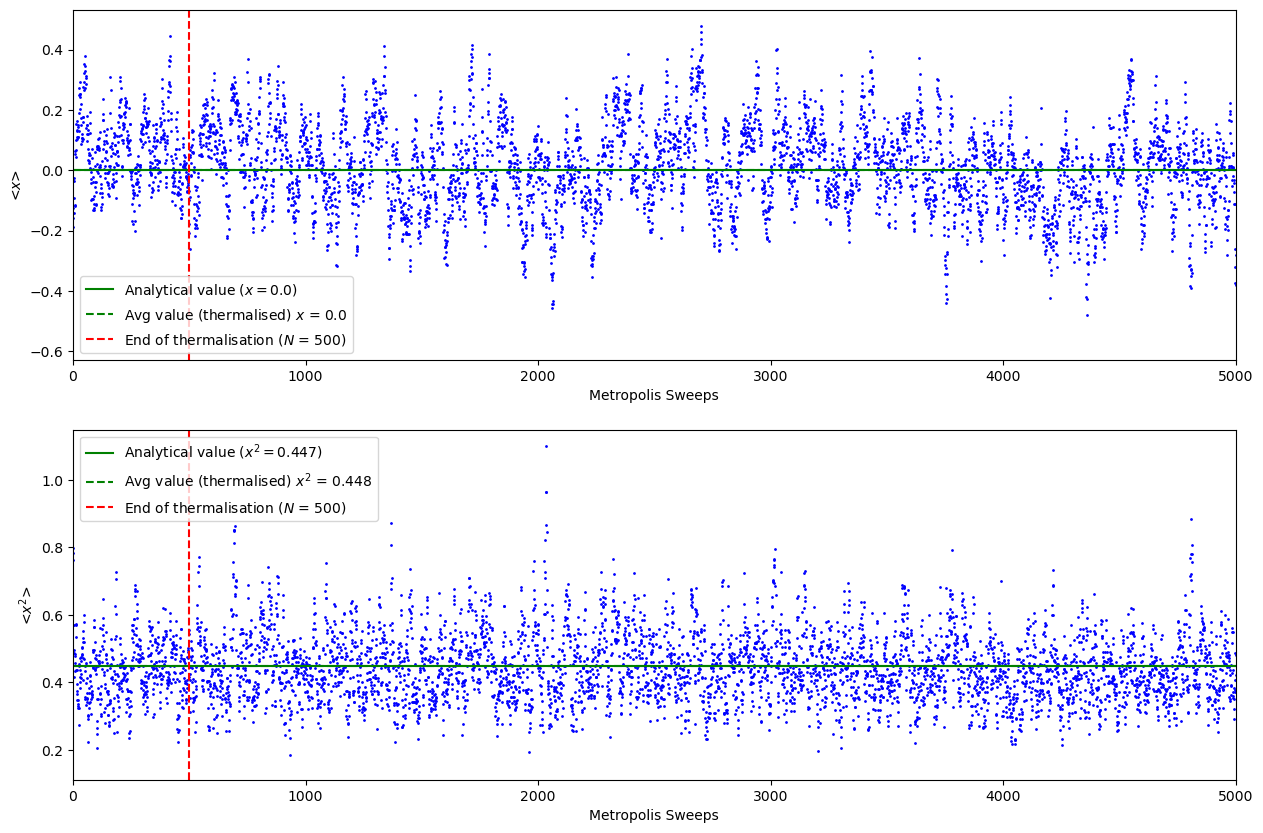

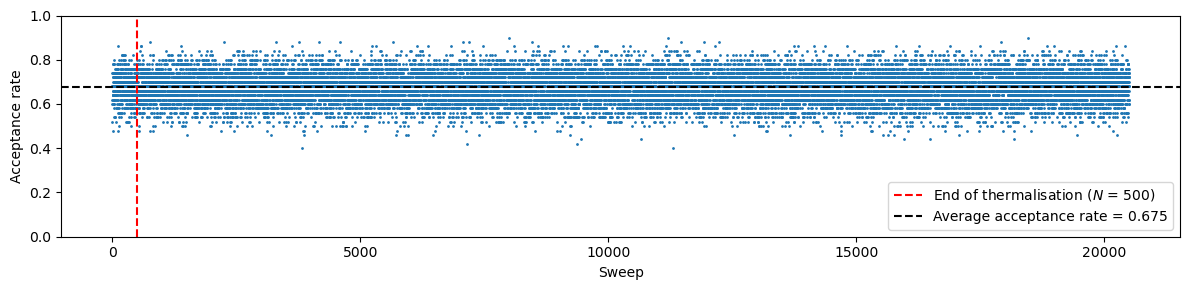

In [26]:
# Expectation values vs. sweeps
sweeps = np.arange(len(x))
fig, ax = plt.subplots(2, 1, figsize=(15,10))
ax[0].plot(sweeps, x, 'o', color="blue", markersize=1)
ax[0].set_xlabel("Metropolis Sweeps")
ax[0].set_ylabel("<$x$>")
#ax[0].set_ylim(-0.25, 0.25)
ax[0].set_xlim(0, 5000)
ax[0].axhline(y=x_analytical, color='g', linestyle='-', label = f"Analytical value ($x={x_analytical}$)")
ax[0].axhline(y=np.mean(x_thermalised), color='g', linestyle='--', label = f"Avg value (thermalised) $x$ = {-np.round(np.mean(x_thermalised), decimals=3)}")
ax[0].axvline(N_therm, color='r', linestyle='--', label = f"End of thermalisation ($N$ = {N_therm})")
ax[0].legend()

ax[1].plot(sweeps, x_2, 'o', color="blue", markersize=1)
ax[1].set_xlabel("Metropolis Sweeps")
ax[1].set_ylabel(rf"<$x^2$>")
#ax[1].set_ylim(0.4, 0.6)
ax[1].set_xlim(0, 5000)
ax[1].axhline(y=x_2_analytical, color='g', linestyle='-', label = f"Analytical value ($x^2={np.round(x_2_analytical, 3)}$)")
ax[1].axhline(y=np.mean(x_2_thermalised), color='g', linestyle='--', label = f"Avg value (thermalised) $x^2$ = {np.round(np.mean(x_2_thermalised), decimals=3)}")
ax[1].axvline(N_therm, color='r', linestyle='--', label = f"End of thermalisation ($N$ = {N_therm})")
ax[1].legend()

# Acceptance rate
plt.figure(figsize=(12,3))
plt.plot(total_acc_rate, '.', markersize=2)
plt.axvline(N_therm, color='red', linestyle='--', label = f"End of thermalisation ($N$ = {N_therm})")
plt.axhline(np.mean(total_acc_rate), linestyle='--', color='black', label=f"Average acceptance rate = {np.round(np.mean(total_acc_rate), decimals=3)}")
plt.ylim(0,1)
plt.xlabel("Sweep")
plt.ylabel("Acceptance rate")
plt.legend()

plt.tight_layout()
plt.show()